# Decision Trees: Hands-on Implementation

In this notebook, we will implement Decision Trees using Python,
explore how they work, and experiment with their performance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(iris.data,columns=iris.feature_names)
df['target'] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
# Features and Target seperation

x = df.drop("target",axis = 1)
y = df['target']

print("Features shape:", x.shape)
print("Target Shape: ",y.shape)

Features shape: (150, 4)
Target Shape:  (150,)


In [3]:
# train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state = 3
)

print(X_train.shape)
print(X_test.shape)

(120, 4)
(30, 4)


In [4]:
#import the model
from sklearn.tree import DecisionTreeClassifier

# load the model
model = DecisionTreeClassifier(random_state = 2)

# train the model
model.fit(X_train,y_train)

DecisionTreeClassifier(random_state=2)

In [5]:
# predict the trained model outputs
y_pred = model.predict(X_test)

print(y_pred[:30])

[0 0 0 0 0 2 1 0 2 1 1 0 1 1 2 0 1 2 2 0 2 2 2 1 0 2 2 1 1 1]


In [6]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test,y_pred)

print("Accuracy: ",accuracy)

Accuracy:  1.0


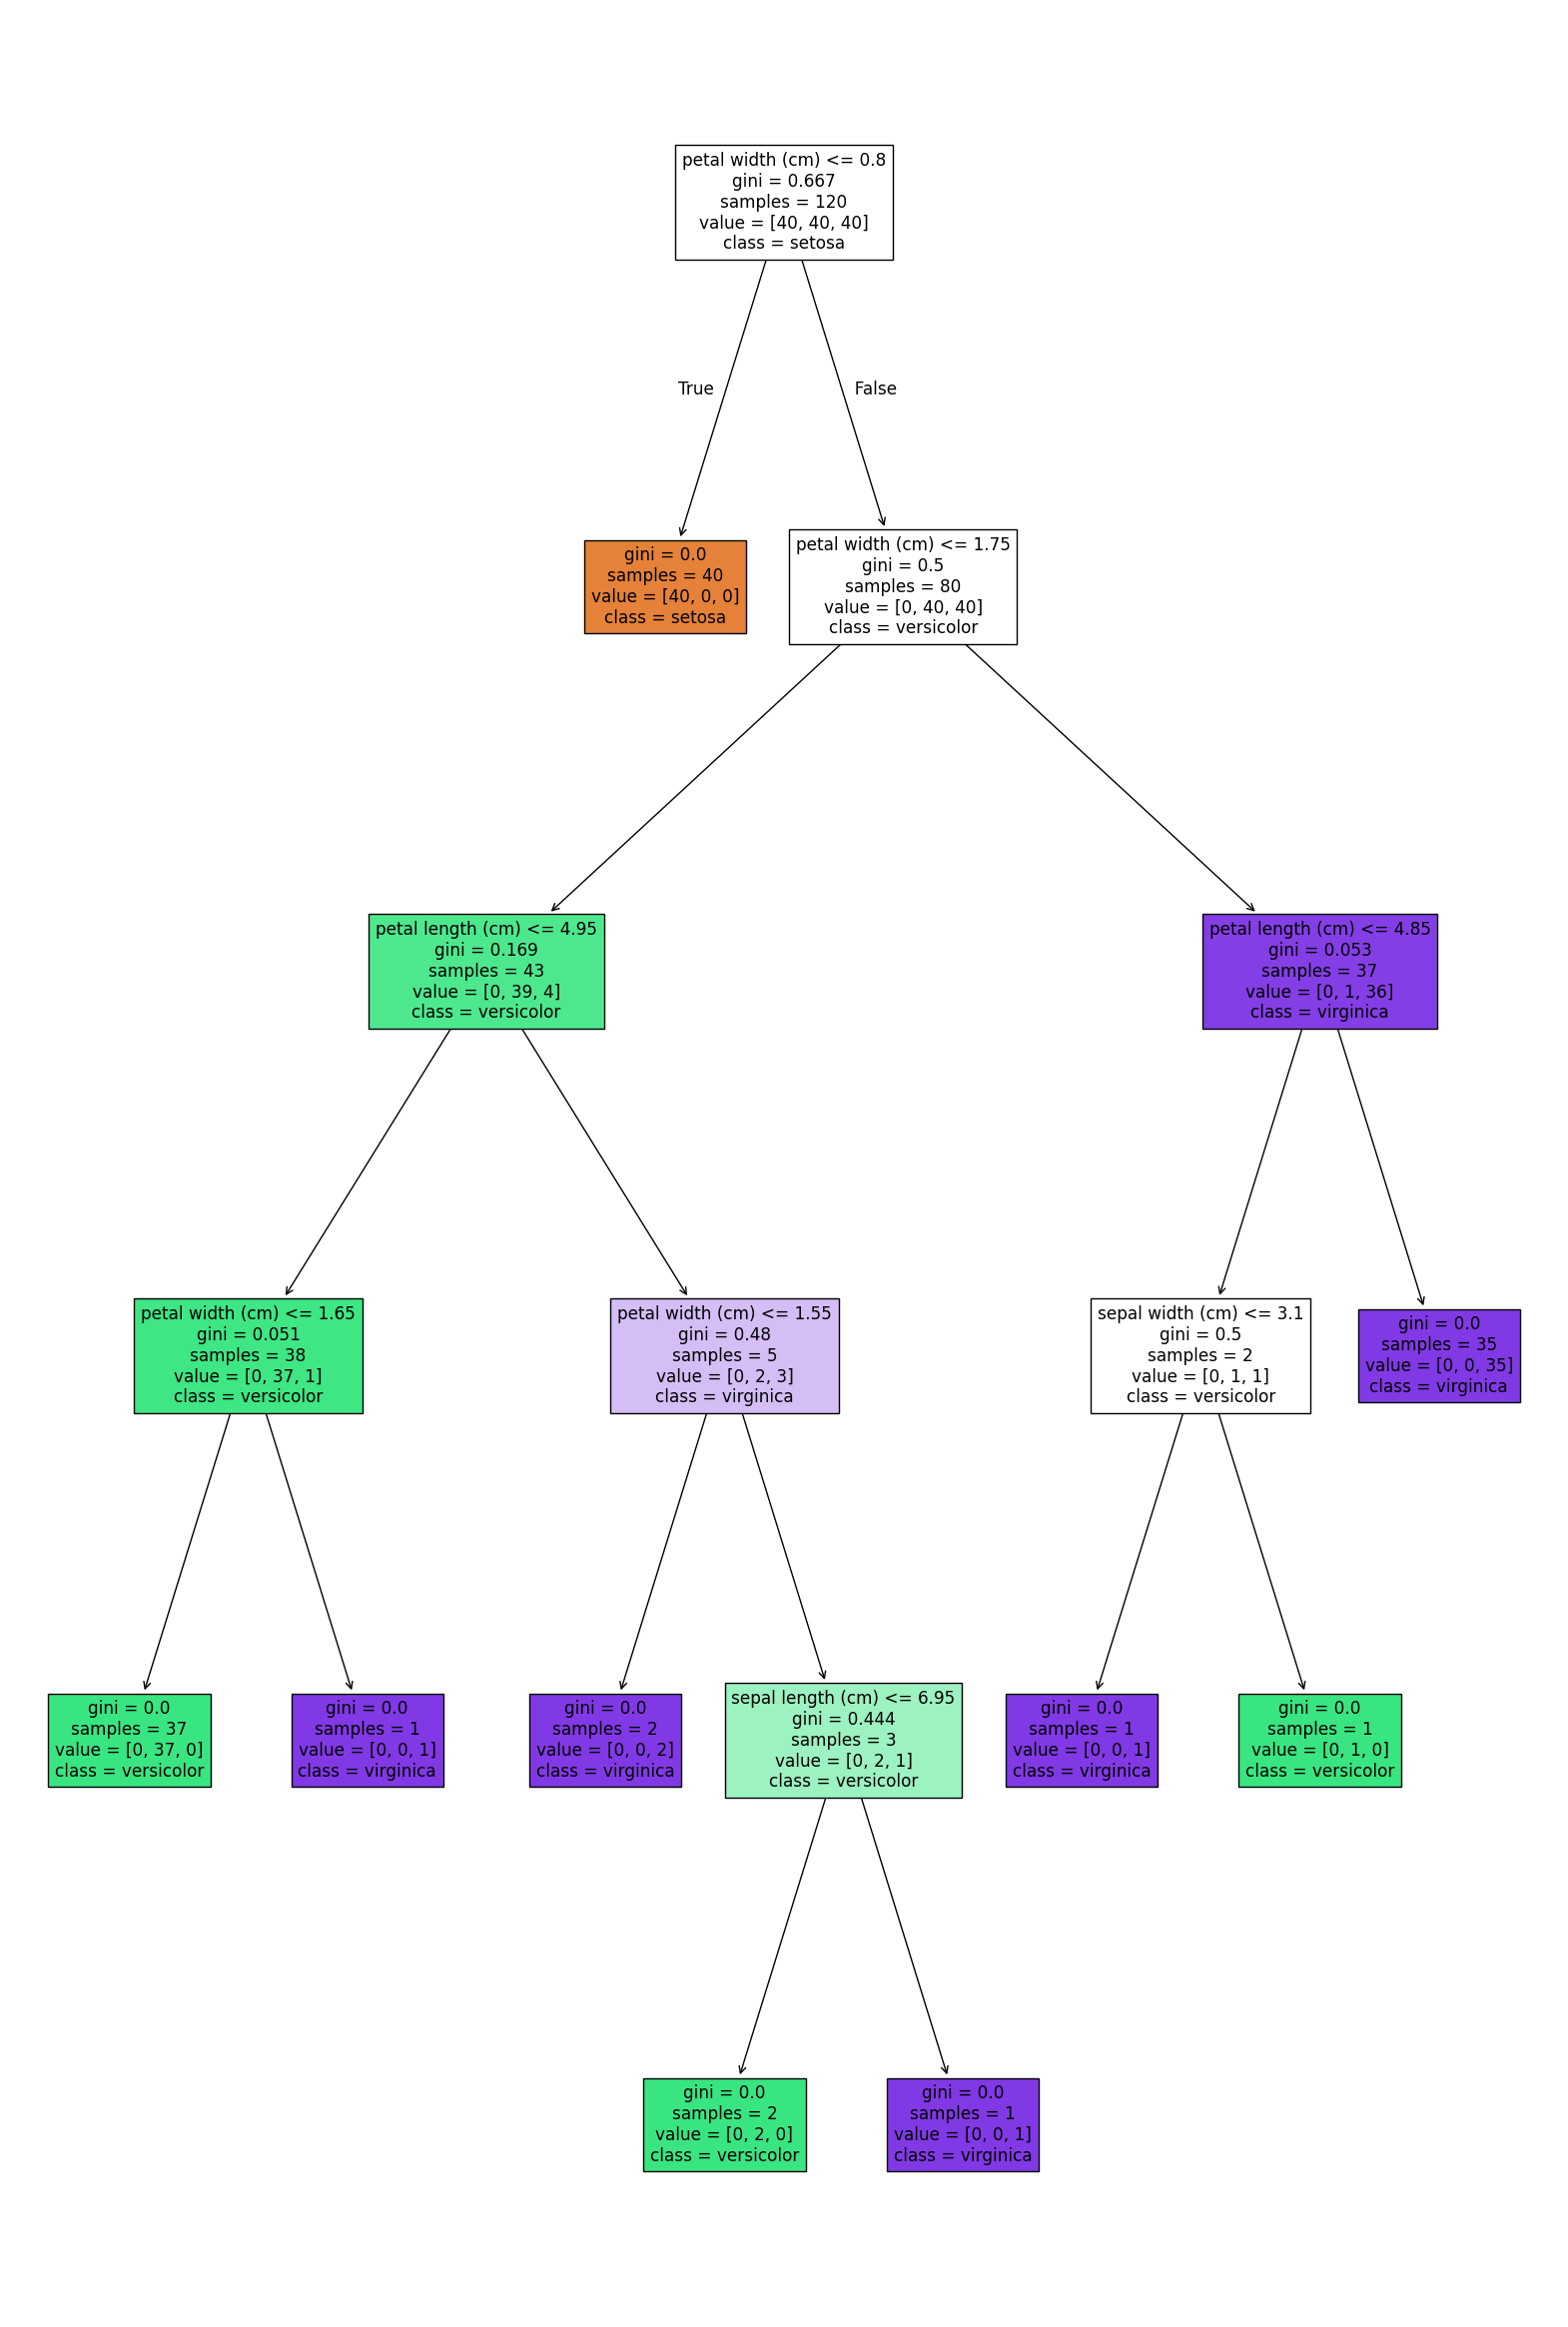

In [7]:
# visualizing the decision tree
from sklearn.tree import plot_tree

plt.figure(figsize=(20,30))

plot_tree(
    model,
    feature_names=x.columns,
    class_names=iris.target_names,
    filled=True
)

plt.show()

In [8]:
# understand trees structure
print("Number of nodes: ",model.tree_.node_count)
print("tree Depth: ",model.get_depth())
print("Number of Leaves: ",model.get_n_leaves())

Number of nodes:  17
tree Depth:  5
Number of Leaves:  9


## Now we will see How increase in depth affects accuracy

In [9]:
# create trees with different depths

for depth in [1,2,3,5,None]:
    clf = DecisionTreeClassifier(max_depth=depth,random_state = 42)
    clf.fit(X_train,y_train)

    train_acc = clf.score(X_train,y_train)
    test_acc = clf.score(X_test,y_test)

    print(f"Depth: {depth}, Train Accuracy: {train_acc:.2f}, Test Accuracy: {test_acc:.2f}")

Depth: 1, Train Accuracy: 0.67, Test Accuracy: 0.67
Depth: 2, Train Accuracy: 0.96, Test Accuracy: 0.93
Depth: 3, Train Accuracy: 0.97, Test Accuracy: 0.97
Depth: 5, Train Accuracy: 0.99, Test Accuracy: 1.00
Depth: None, Train Accuracy: 1.00, Test Accuracy: 0.97


### Understanding Tree Complexity

The complexity of a Decision Tree is mainly determined by its **depth** and its **number of leaves**.

- A **shallow tree** (small depth, few leaves) makes simple decisions. It may miss patterns in the data (**underfitting**).
- A **deep tree** (large depth, many leaves) can carve the data into very small groups. It fits the training data extremely well, but may just be memorizing it (**overfitting**).

The goal is to find a middle ground: a tree complex enough to capture real patterns, but simple enough to generalize to new data.

Below, we extend the depth experiment to also track the tree's actual depth and number of leaves, so we can see how complexity grows with `max_depth`.

In [10]:
# experiment: how max_depth affects accuracy AND complexity
results = []

for depth in [1, 2, 3, 5, None]:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(X_train, y_train)

    results.append({
        "max_depth": str(depth),
        "Train Accuracy": clf.score(X_train, y_train),
        "Test Accuracy": clf.score(X_test, y_test),
        "Actual Depth": clf.get_depth(),
        "Number of Leaves": clf.get_n_leaves()
    })

complexity_df = pd.DataFrame(results)
print(complexity_df)

  max_depth  Train Accuracy  Test Accuracy  Actual Depth  Number of Leaves
0         1        0.666667       0.666667             1                 2
1         2        0.958333       0.933333             2                 3
2         3        0.966667       0.966667             3                 5
3         5        0.991667       1.000000             5                 9
4      None        1.000000       0.966667             6                10


## Overfitting in Decision Trees

**Overfitting** happens when a model learns the training data *too well* — including its noise and quirks — instead of the general pattern. An overfit model performs great on the data it was trained on, but worse on new, unseen data.

Decision Trees are especially prone to overfitting because, if left unrestricted, they keep splitting until every leaf is pure (contains samples of only one class).

**How to spot it:** compare training accuracy and testing accuracy.
- Training accuracy near 100% with noticeably lower testing accuracy ⟹ the tree is likely overfitting.
- The bigger the gap, the stronger the overfitting.

Let's train a completely unrestricted tree and check for this gap.

In [11]:
# train an unrestricted tree (no limits on growth)
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)

full_train_acc = full_tree.score(X_train, y_train)
full_test_acc = full_tree.score(X_test, y_test)

print("Unrestricted Decision Tree")
print(f"Train Accuracy: {full_train_acc:.2f}")
print(f"Test Accuracy:  {full_test_acc:.2f}")
print(f"Gap (Train - Test): {full_train_acc - full_test_acc:.2f}")
print(f"Tree Depth: {full_tree.get_depth()}")
print(f"Number of Leaves: {full_tree.get_n_leaves()}")

Unrestricted Decision Tree
Train Accuracy: 1.00
Test Accuracy:  0.97
Gap (Train - Test): 0.03
Tree Depth: 6
Number of Leaves: 10


## Pre-pruning (Early Stopping)

**Pre-pruning** means stopping the tree from growing too large *while it is being built*. We set limits before training, and the tree is not allowed to break them.

Common pre-pruning parameters in scikit-learn:

| Parameter | What it does |
|---|---|
| `max_depth` | Maximum depth the tree can reach |
| `min_samples_split` | Minimum samples a node must have to be split further |
| `min_samples_leaf` | Minimum samples every leaf must contain |

These constraints force the tree to stay simpler, which usually reduces overfitting.

In [12]:
# train a pre-pruned tree with growth restrictions
prepruned_tree = DecisionTreeClassifier(
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
prepruned_tree.fit(X_train, y_train)

pre_train_acc = prepruned_tree.score(X_train, y_train)
pre_test_acc = prepruned_tree.score(X_test, y_test)

print("Pre-pruned Decision Tree")
print(f"Train Accuracy: {pre_train_acc:.2f}")
print(f"Test Accuracy:  {pre_test_acc:.2f}")
print(f"Gap (Train - Test): {pre_train_acc - pre_test_acc:.2f}")
print(f"Tree Depth: {prepruned_tree.get_depth()}")
print(f"Number of Leaves: {prepruned_tree.get_n_leaves()}")

Pre-pruned Decision Tree
Train Accuracy: 0.96
Test Accuracy:  0.97
Gap (Train - Test): -0.01
Tree Depth: 3
Number of Leaves: 5


## Post-pruning (Cost-Complexity Pruning)

**Post-pruning** takes the opposite approach: first grow the full tree, then *cut back* branches that add complexity without improving performance.

Scikit-learn implements this as **cost-complexity pruning**, controlled by the parameter `ccp_alpha`:

- `ccp_alpha = 0` ⟹ no pruning (the full tree).
- Larger `ccp_alpha` ⟹ more aggressive pruning ⟹ smaller, simpler tree.

The method `cost_complexity_pruning_path()` gives us the sequence of effective alpha values for our training data. We can train one tree per alpha and see how accuracy changes as the tree gets pruned harder.

Effective alphas: [0.     0.0081 0.0083 0.0162 0.0192 0.2567 0.3333]


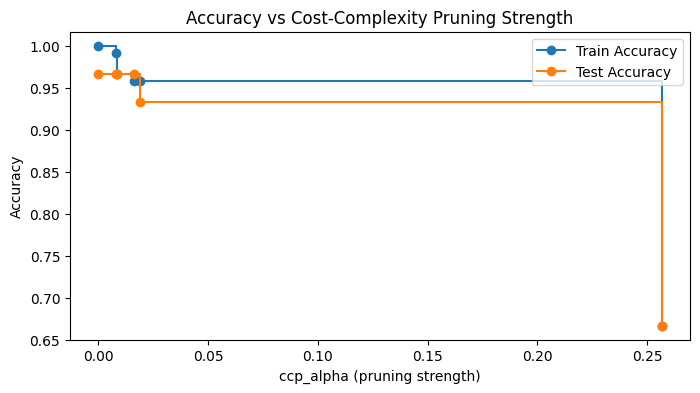

In [13]:
# get the sequence of effective alphas for cost-complexity pruning
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

print("Effective alphas:", np.round(ccp_alphas, 4))

# train one tree per alpha (drop the last alpha, which prunes to a single node)
pruned_trees = []
for alpha in ccp_alphas[:-1]:
    clf = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    clf.fit(X_train, y_train)
    pruned_trees.append(clf)

train_scores = [clf.score(X_train, y_train) for clf in pruned_trees]
test_scores = [clf.score(X_test, y_test) for clf in pruned_trees]

# plot accuracy vs pruning strength
plt.figure(figsize=(8, 4))
plt.plot(ccp_alphas[:-1], train_scores, marker="o", label="Train Accuracy", drawstyle="steps-post")
plt.plot(ccp_alphas[:-1], test_scores, marker="o", label="Test Accuracy", drawstyle="steps-post")
plt.xlabel("ccp_alpha (pruning strength)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Cost-Complexity Pruning Strength")
plt.legend()
plt.show()

In [14]:
# pick the alpha with the best test accuracy and train the final post-pruned tree
best_idx = int(np.argmax(test_scores))
best_alpha = ccp_alphas[best_idx]

postpruned_tree = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42)
postpruned_tree.fit(X_train, y_train)

post_train_acc = postpruned_tree.score(X_train, y_train)
post_test_acc = postpruned_tree.score(X_test, y_test)

print(f"Best ccp_alpha: {best_alpha:.4f}")
print("Post-pruned Decision Tree")
print(f"Train Accuracy: {post_train_acc:.2f}")
print(f"Test Accuracy:  {post_test_acc:.2f}")
print(f"Tree Depth: {postpruned_tree.get_depth()}")
print(f"Number of Leaves: {postpruned_tree.get_n_leaves()}")

Best ccp_alpha: 0.0000
Post-pruned Decision Tree
Train Accuracy: 1.00
Test Accuracy:  0.97
Tree Depth: 6
Number of Leaves: 10


## Comparison: Unrestricted vs Pre-pruned vs Post-pruned

Now let's put the three trees side by side and compare their accuracy and complexity.

In [15]:
# compare the three trees
comparison = pd.DataFrame({
    "Model": ["Unrestricted", "Pre-pruned", "Post-pruned"],
    "Train Accuracy": [
        full_tree.score(X_train, y_train),
        prepruned_tree.score(X_train, y_train),
        postpruned_tree.score(X_train, y_train)
    ],
    "Test Accuracy": [
        full_tree.score(X_test, y_test),
        prepruned_tree.score(X_test, y_test),
        postpruned_tree.score(X_test, y_test)
    ],
    "Depth": [
        full_tree.get_depth(),
        prepruned_tree.get_depth(),
        postpruned_tree.get_depth()
    ],
    "Number of Leaves": [
        full_tree.get_n_leaves(),
        prepruned_tree.get_n_leaves(),
        postpruned_tree.get_n_leaves()
    ]
})

print(comparison)

          Model  Train Accuracy  Test Accuracy  Depth  Number of Leaves
0  Unrestricted        1.000000       0.966667      6                10
1    Pre-pruned        0.958333       0.966667      3                 5
2   Post-pruned        1.000000       0.966667      6                10


### Takeaway

- The **unrestricted** tree achieves the highest training accuracy but is the most complex, and the train–test gap reveals overfitting.
- The **pre-pruned** tree is much simpler because we limited its growth up front; it usually generalizes better.
- The **post-pruned** tree lets the data decide how much to cut back, often giving a good balance of simplicity and test accuracy.

In practice, both pruning styles are used: pre-pruning is simple and fast, while post-pruning (tuning `ccp_alpha`, e.g. with cross-validation) is more systematic.


## Gini Impurity vs Entropy

Both Gini Impurity and Entropy measure how mixed the classes are in a node. Decision Trees use them to find good splits.

### 1. Gini Impurity

Gini measures the probability of incorrectly classifying a randomly selected sample if its class is assigned according to the class distribution in that node.

Formula:

$$
Gini = 1 - \sum_{i=1}^{C} p_i^2
$$

### 2. Entropy

Entropy measures the uncertainty or randomness in the class distribution of a node.

Formula:

$$
Entropy = -\sum_{i=1}^{C} p_i \log_2(p_i)
$$

Here, \(p_i\) is the proportion of samples belonging to class \(i\), and \(C\) is the number of classes. For entropy, terms with \(p_i=0\) are treated as zero.

### 3. Key Differences

| Property | Gini Impurity | Entropy |
|---|---|---|
| Measures | Impurity | Uncertainty |
| Formula | \(1-\sum p_i^2\) | \(-\sum p_i\log_2(p_i)\) |
| Pure node | 0 | 0 |
| Computation | Generally faster | Generally slower due to logarithms |
| Scikit-learn | `criterion="gini"` | `criterion="entropy"` |

### 4. Important Observation

Both metrics are zero when a node contains samples from only one class. They are higher when classes are more mixed.

For a binary classification problem with equal proportions (50%–50%):
- Gini Impurity = 0.5
- Entropy = 1.0 bit

The two criteria may select different splits, but they often produce similar trees.


In [16]:
# compare different splittin criteria 
for criterion in ["gini","entropy"]:
    clf = DecisionTreeClassifier(
        criterion = criterion,
        max_depth = 3,
        random_state = 2
    )
    clf.fit(X_train,y_train)

    print(
        f"{criterion} - "
        f"Train Accuracy: {clf.score(X_train, y_train):.2f}, "
        f"Test Accuracy: {clf.score(X_test, y_test):.2f}"
    )

gini - Train Accuracy: 0.97, Test Accuracy: 0.97
entropy - Train Accuracy: 0.97, Test Accuracy: 0.97


             Feature  Importance
3   petal width (cm)    0.922653
2  petal length (cm)    0.048180
0  sepal length (cm)    0.016667
1   sepal width (cm)    0.012500


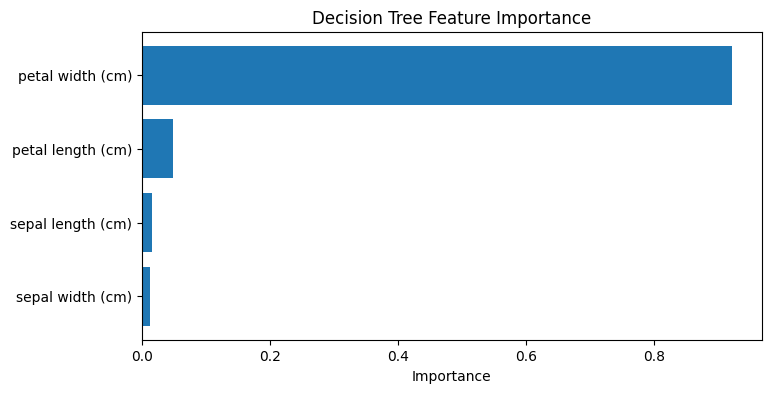

In [17]:
# displaay feature importance

importance = pd.DataFrame({
    "Feature" : x.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by = "Importance",ascending = False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(8, 4))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Decision Tree Feature Importance")
plt.gca().invert_yaxis()
plt.show()